# MobileNetV1 — Depthwise Separable Convolutions

**Paper:** Howard, A. G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M., & Adam, H. (2017).  
*MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications.*  
arXiv:1704.04861. [[PDF]](https://arxiv.org/abs/1704.04861)

**Venue:** Google Inc. Technical Report, April 2017.

---

## Overview

MobileNetV1 introduced **Depthwise Separable Convolution** to make deep CNNs tractable for mobile and embedded devices. The insight is that a standard k×k convolution can be factorised into two cheaper operations:

1. **Depthwise conv** (k×k, groups=C_in): spatial filtering, one filter per input channel
2. **Pointwise conv** (1×1): linear cross-channel combination

**Cost reduction** (k=3, C_out=512): ~8.6× fewer MACs than a standard 3×3 conv.

A **width multiplier α** ∈ {0.25, 0.5, 0.75, 1.0} uniformly scales all channel counts,
giving a continuous accuracy/efficiency trade-off.

> 📄 **Paper:** Howard et al. (2017). MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications. arXiv.
> 🔗 **Link:** <https://arxiv.org/abs/1704.04861>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/mobilenet_v1.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["conv 3×3 /2 · BN · ReLU → 32α"]:::stage
  STEM --> S["13 depthwise-separable blocks<br/>strides /4 /8 /16 /32, widths ×α"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph DS["depthwise-separable conv"]
    direction LR
    X["x (C_in)"] --> DW["3×3 depthwise (groups = C_in) · BN · ReLU"]:::block --> PW["1×1 pointwise → C_out · BN · ReLU"]:::block
  end
  S -.-> DS
  NOTE["cost ≈ 1/C_out + 1/9 of a full 3×3 conv"]:::block -.-> DS
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram (ASCII)

```
Input [B, 3, H, W]
    │
    ▼
┌────────────────────────────────────────────────────────┐
│  STEM                                                  │
│  Conv(3→32, 3×3, s2) + BN + ReLU → H/2                │
│  DWSConv(32→64, s1)                                    │
└────────────────────────────────────────────────────────┘
    │  [B, 64, H/2, W/2]
    ▼
┌────────────────────────────────────────────────────────┐
│  STAGE 0                                               │
│  DWSConv(64→128, s2) → DWSConv(128→128, s1)           │
└────────────────────────────────────────────────────────┘
    │  [B, 128, H/4, W/4]   ← feature_maps[0]
    ▼
┌────────────────────────────────────────────────────────┐
│  STAGE 1                                               │
│  DWSConv(128→256, s2) → DWSConv(256→256, s1)          │
└────────────────────────────────────────────────────────┘
    │  [B, 256, H/8, W/8]   ← feature_maps[1]
    ▼
┌────────────────────────────────────────────────────────┐
│  STAGE 2                                               │
│  DWSConv(256→512, s2) → 5×DWSConv(512→512, s1)        │
└────────────────────────────────────────────────────────┘
    │  [B, 512, H/16, W/16]  ← feature_maps[2]
    ▼
┌────────────────────────────────────────────────────────┐
│  STAGE 3                                               │
│  DWSConv(512→1024, s2) → DWSConv(1024→1024, s1)       │
└────────────────────────────────────────────────────────┘
    │  [B, 1024, H/32, W/32] ← feature_maps[3]
    ▼
  GlobalAvgPool → Dropout → [B, 1024] = pooled_output
```

**DWSConv block** internals:
```
  DW: Conv(C→C, 3×3, groups=C) + BN + ReLU  ← spatial filtering
  PW: Conv(C→C', 1×1)          + BN + ReLU  ← channel mixing
```

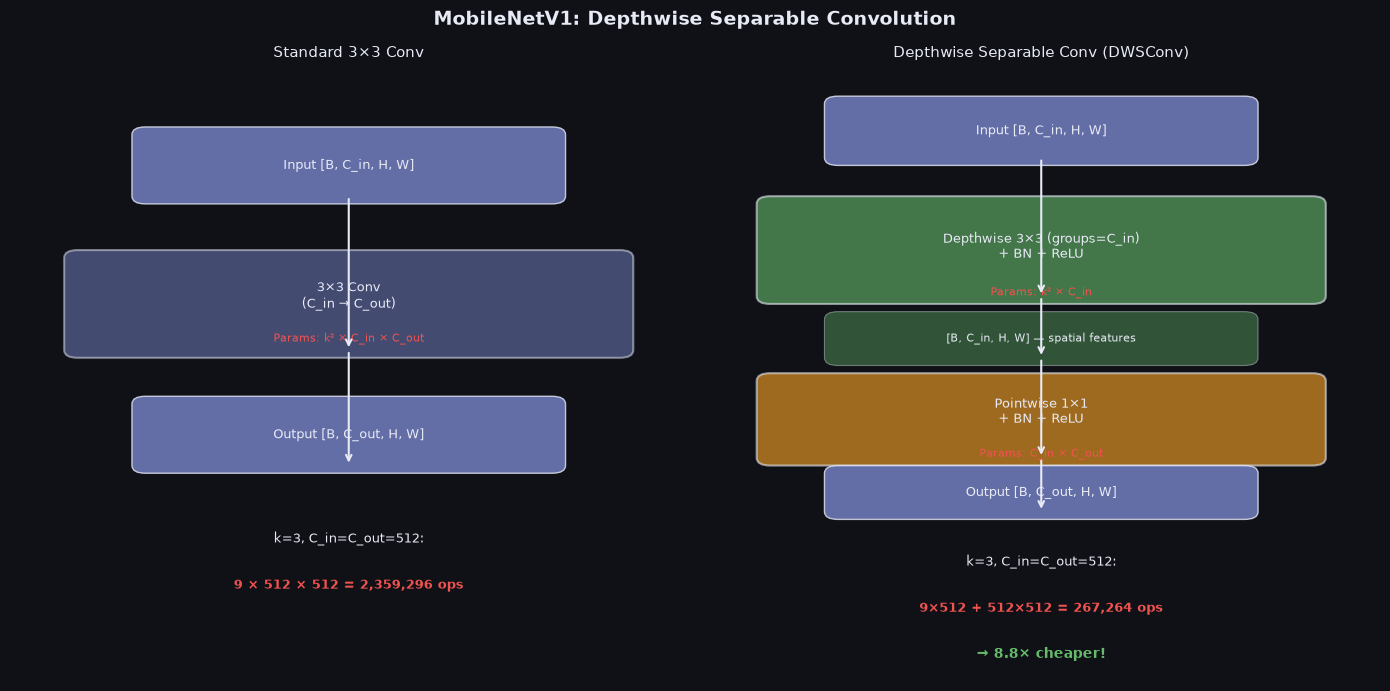

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

BG   = '#0f1117'
FG   = '#e8eaf6'
ACC1 = '#7986cb'  # standard conv
ACC2 = '#66bb6a'  # depthwise conv
ACC3 = '#ffa726'  # pointwise conv
ACC4 = '#ef5350'  # cost label

fig, axes = plt.subplots(1, 2, figsize=(14, 7), facecolor=BG)
fig.suptitle('MobileNetV1: Depthwise Separable Convolution', color=FG, fontsize=14, fontweight='bold')

# ── Left panel: Standard conv ─────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(0, 5); ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title('Standard 3×3 Conv', color=FG, fontsize=11)

# Input
ax.add_patch(FancyBboxPatch((1, 6.3), 3, 0.8, boxstyle='round,pad=0.1', fc=ACC1, alpha=0.8, ec=FG, lw=1))
ax.text(2.5, 6.7, 'Input [B, C_in, H, W]', ha='center', va='center', color=FG, fontsize=9)

# Conv block
ax.add_patch(FancyBboxPatch((0.5, 4.3), 4, 1.2, boxstyle='round,pad=0.1', fc=ACC1, alpha=0.5, ec=FG, lw=1.5))
ax.text(2.5, 5.0, '3×3 Conv\n(C_in → C_out)', ha='center', va='center', color=FG, fontsize=9)
ax.text(2.5, 4.45, f'Params: k² × C_in × C_out', ha='center', va='center', color=ACC4, fontsize=8)

# Arrow
ax.annotate('', xy=(2.5, 4.3), xytext=(2.5, 6.3), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Output
ax.add_patch(FancyBboxPatch((1, 2.8), 3, 0.8, boxstyle='round,pad=0.1', fc=ACC1, alpha=0.8, ec=FG, lw=1))
ax.text(2.5, 3.2, 'Output [B, C_out, H, W]', ha='center', va='center', color=FG, fontsize=9)
ax.annotate('', xy=(2.5, 2.8), xytext=(2.5, 4.3), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Cost for k=3, C_in=C_out=512
ax.text(2.5, 1.8, 'k=3, C_in=C_out=512:', ha='center', color=FG, fontsize=9)
ax.text(2.5, 1.2, '9 × 512 × 512 = 2,359,296 ops', ha='center', color=ACC4, fontsize=9, fontweight='bold')

# ── Right panel: Depthwise Separable ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(0, 5); ax2.set_ylim(0, 8)
ax2.axis('off')
ax2.set_title('Depthwise Separable Conv (DWSConv)', color=FG, fontsize=11)

# Input
ax2.add_patch(FancyBboxPatch((1, 6.8), 3, 0.7, boxstyle='round,pad=0.1', fc=ACC1, alpha=0.8, ec=FG, lw=1))
ax2.text(2.5, 7.15, 'Input [B, C_in, H, W]', ha='center', va='center', color=FG, fontsize=9)

# Depthwise block
ax2.add_patch(FancyBboxPatch((0.5, 5.0), 4, 1.2, boxstyle='round,pad=0.1', fc=ACC2, alpha=0.6, ec=FG, lw=1.5))
ax2.text(2.5, 5.65, 'Depthwise 3×3 (groups=C_in)\n+ BN + ReLU', ha='center', va='center', color=FG, fontsize=9)
ax2.text(2.5, 5.05, 'Params: k² × C_in', ha='center', va='center', color=ACC4, fontsize=8)
ax2.annotate('', xy=(2.5, 5.0), xytext=(2.5, 6.8), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Intermediate
ax2.add_patch(FancyBboxPatch((1, 4.2), 3, 0.5, boxstyle='round,pad=0.1', fc=ACC2, alpha=0.4, ec=FG, lw=0.8))
ax2.text(2.5, 4.45, '[B, C_in, H, W] — spatial features', ha='center', va='center', color=FG, fontsize=8)
ax2.annotate('', xy=(2.5, 4.2), xytext=(2.5, 5.0), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Pointwise block
ax2.add_patch(FancyBboxPatch((0.5, 2.9), 4, 1.0, boxstyle='round,pad=0.1', fc=ACC3, alpha=0.6, ec=FG, lw=1.5))
ax2.text(2.5, 3.5, 'Pointwise 1×1\n+ BN + ReLU', ha='center', va='center', color=FG, fontsize=9)
ax2.text(2.5, 2.95, 'Params: C_in × C_out', ha='center', va='center', color=ACC4, fontsize=8)
ax2.annotate('', xy=(2.5, 2.9), xytext=(2.5, 4.2), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Output
ax2.add_patch(FancyBboxPatch((1, 2.2), 3, 0.5, boxstyle='round,pad=0.1', fc=ACC1, alpha=0.8, ec=FG, lw=1))
ax2.text(2.5, 2.45, 'Output [B, C_out, H, W]', ha='center', va='center', color=FG, fontsize=9)
ax2.annotate('', xy=(2.5, 2.2), xytext=(2.5, 2.9), arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))

# Cost
ax2.text(2.5, 1.5, 'k=3, C_in=C_out=512:', ha='center', color=FG, fontsize=9)
ax2.text(2.5, 0.9, '9×512 + 512×512 = 267,264 ops', ha='center', color=ACC4, fontsize=9, fontweight='bold')
ax2.text(2.5, 0.3, '→ 8.8× cheaper!', ha='center', color='#66bb6a', fontsize=10, fontweight='bold')

plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations & Mathematics

### Depthwise Separable Convolution

**Standard 3×3 Conv** computes:
$$\mathbf{G}_{k,l,n} = \sum_{i,j,m} \mathbf{K}_{i,j,m,n} \cdot \mathbf{F}_{k+i-1, l+j-1, m}$$

Computational cost: $D_K^2 \cdot M \cdot N \cdot D_F^2$ (where $D_K$=kernel size, $M$=input channels, $N$=output channels, $D_F$=feature map size)

**Depthwise Separable** factorises this into:

1. **Depthwise** (spatial):
$$\hat{\mathbf{G}}_{k,l,m} = \sum_{i,j} \hat{\mathbf{K}}_{i,j,m} \cdot \mathbf{F}_{k+i-1, l+j-1, m}$$
Cost: $D_K^2 \cdot M \cdot D_F^2$

2. **Pointwise** (channel mixing):
$$\mathbf{G}_{k,l,n} = \sum_m \mathbf{W}_{m,n} \cdot \hat{\mathbf{G}}_{k,l,m}$$
Cost: $M \cdot N \cdot D_F^2$

**Reduction ratio:**
$$\frac{D_K^2 \cdot M \cdot D_F^2 + M \cdot N \cdot D_F^2}{D_K^2 \cdot M \cdot N \cdot D_F^2} = \frac{1}{N} + \frac{1}{D_K^2}$$

For $D_K=3, N=512$: reduction ≈ $\frac{1}{512} + \frac{1}{9} \approx 0.113$ → **~8.8× cheaper**.

### Width Multiplier α

All channel counts scaled by $\alpha \in \{0.25, 0.5, 0.75, 1.0\}$:
$$\text{cost}(\alpha) \approx \alpha^2 \cdot \text{cost}(1.0)$$

| Model | α | MACs | Top-1 Acc (ImageNet) |
|-------|---|------|---------------------|
| V1-100 | 1.0 | 569M | 70.6% |
| V1-075 | 0.75 | 325M | 68.4% |
| V1-050 | 0.5 | 149M | 63.7% |
| V1-025 | 0.25 | 41M  | 50.6% |

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/mobilenet_v1.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/mobilenet_v1.py</code></summary>

```text
MobileNetV1 Vision Backbones
=============================

Implements the MobileNetV1 family (Howard et al. 2017, "MobileNets: Efficient
Convolutional Neural Networks for Mobile Vision Applications").

Reference: https://arxiv.org/abs/1704.04861

Architecture
------------
MobileNetV1 replaces standard 3×3 convolutions with **Depthwise Separable
Convolutions**, which factorise a spatial + channel operation into two cheaper
operations:

  1. Depthwise conv: k×k, groups=C_in — spatial feature extraction per channel.
  2. Pointwise conv: 1×1 standard     — linear cross-channel combination.

Computation cost ratio vs standard conv:
    DW+PW / Standard = (k²·C_in + C_in·C_out) / (k²·C_in·C_out)
                     = 1/C_out + 1/k²
    For k=3, C_out=512 → ~8.6× reduction.

Stage structure (α=1.0):
  Stem    : Conv(3→32, 3×3, s2) + BN + ReLU → DWSConv(32→64, s1)  → H/2
  Stage 0 : DWSConv(64→128,  s2) → DWSConv(128→128,  s1)           → H/4
  Stage 1 : DWSConv(128→256, s2) → DWSConv(256→256,  s1)           → H/8
  Stage 2 : DWSConv(256→512, s2) → 5×DWSConv(512→512, s1)          → H/16
  Stage 3 : DWSConv(512→1024,s2) → DWSConv(1024→1024,s1)           → H/32
  Head    : GlobalAvgPool → [B, embed_dim]

All channels are scaled by width multiplier α ∈ {0.25, 0.5, 0.75, 1.0}.
  embed_dim = int(1024 * α)
  feature_dims = [int(c*α) for c in [64, 128, 256, 512, 1024]]

Registered names
----------------
  mobilenet_v1_025 — α=0.25, embed_dim=256
  mobilenet_v1_050 — α=0.50, embed_dim=512
  mobilenet_v1_075 — α=0.75, embed_dim=768
  mobilenet_v1_100 — α=1.00, embed_dim=1024

Citation
--------
  Howard, A. G. et al. (2017). MobileNets: Efficient Convolutional Neural
  Networks for Mobile Vision Applications. arXiv:1704.04861.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/mobilenet_v1.py`, definition by definition

**`_DWSConv`** - Depthwise Separable Convolution block with BN+ReLU after each conv.

In [5]:
class _DWSConv(nn.Module):
    """Depthwise Separable Convolution block with BN+ReLU after each conv.

    Factorises a standard k×k conv into:
      1. Depthwise k×k (groups=in_chs)  — spatial mixing per channel
      2. Pointwise 1×1                  — cross-channel mixing

    Args:
        in_chs:  Input channels.
        out_chs: Output channels.
        stride:  Spatial stride applied to the depthwise conv.
    """

    def __init__(self, in_chs: int, out_chs: int, stride: int = 1) -> None:
        super().__init__()
        pad = 1
        self.dw = nn.Sequential(
            # Depthwise: each input channel filtered independently
            nn.Conv2d(in_chs, in_chs, kernel_size=3, stride=stride,
                      padding=pad, groups=in_chs, bias=False),
            nn.BatchNorm2d(in_chs),
            nn.ReLU(inplace=True),
        )
        self.pw = nn.Sequential(
            # Pointwise: 1×1 cross-channel projection
            nn.Conv2d(in_chs, out_chs, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.pw(self.dw(x))

**`MobileNetV1`** - MobileNetV1 backbone with width multiplier.

In [6]:
class MobileNetV1(BaseVisionBackbone):
    """MobileNetV1 backbone with width multiplier.

    Returns 4-scale feature maps (one per stride-2 stage) and a global pooled
    embedding for use with VLM projectors and action encoders.

    Args:
        alpha:      Width multiplier ∈ {0.25, 0.5, 0.75, 1.0}.  Scales all
                    channel counts linearly; controls accuracy/efficiency trade-off.
        img_size:   Expected input spatial resolution.
        in_chans:   Input image channels.
        drop_rate:  Dropout after global pool.
        out_indices: Which stages to include in feature_maps.
    """

    arch_name: str       = "mobilenet_v1"
    embed_dim: int       = 1024
    feature_dims: list[int] = [64, 128, 256, 512, 1024]

    def __init__(
        self,
        alpha:       float     = 1.0,
        img_size:    int       = 224,
        in_chans:    int       = 3,
        drop_rate:   float     = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        def _c(n: int) -> int:
            """Scale channel count by alpha, ensure minimum 1."""
            return max(1, int(n * alpha))

        self.embed_dim   = _c(1024)
        self.feature_dims = [_c(64), _c(128), _c(256), _c(512), _c(1024)]

        # ── Stem: standard Conv + first DWSConv ───────────────────────────────
        # One standard conv at input (depthwise on 3-channel input is odd),
        # then immediately a DWSConv to the first stage output channels.
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, _c(32), kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(_c(32)),
            nn.ReLU(inplace=True),
            _DWSConv(_c(32), _c(64), stride=1),
        )

        # ── Stages — each starts with a stride-2 DWSConv then stride-1 blocks ─
        # Stage 0: 64→128 (s2) → 128→128 (s1)
        self.stage0 = nn.Sequential(
            _DWSConv(_c(64),  _c(128), stride=2),
            _DWSConv(_c(128), _c(128), stride=1),
        )

        # Stage 1: 128→256 (s2) → 256→256 (s1)
        self.stage1 = nn.Sequential(
            _DWSConv(_c(128), _c(256), stride=2),
            _DWSConv(_c(256), _c(256), stride=1),
        )

        # Stage 2: 256→512 (s2) → 5×512→512 (s1) — most compute here
        self.stage2 = nn.Sequential(
            _DWSConv(_c(256), _c(512), stride=2),
            *[_DWSConv(_c(512), _c(512), stride=1) for _ in range(5)],
        )

        # Stage 3: 512→1024 (s2) → 1024→1024 (s1)
        self.stage3 = nn.Sequential(
            _DWSConv(_c(512),  _c(1024), stride=2),
            _DWSConv(_c(1024), _c(1024), stride=1),
        )

        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]
        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run MobileNetV1 forward pass.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, embed_dim]
              feature_maps  — [s0, s1, s2, s3] at strides [4, 8, 16, 32]
        """
        x = self.stem(x)       # [B, _c(64), H/2, W/2]

        s0 = self.stage0(x)    # [B, _c(128), H/4, W/4]
        s1 = self.stage1(s0)   # [B, _c(256), H/8, W/8]
        s2 = self.stage2(s1)   # [B, _c(512), H/16, W/16]
        s3 = self.stage3(s2)   # [B, _c(1024), H/32, W/32]

        pooled = self.dropout(self.pool(s3).flatten(1))

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0..stage (inclusive).

        Args:
            stage: 0-based index, must be in [0, 3].
        """
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`MobileNetV1_025`** - MobileNetV1 α=0.25 — ultra-lightweight, ~0.5M params, embed_dim=256.

In [7]:
@register_vision_backbone("mobilenet_v1_025")
class MobileNetV1_025(MobileNetV1):
    """MobileNetV1 α=0.25 — ultra-lightweight, ~0.5M params, embed_dim=256."""
    arch_name    = "mobilenet_v1_025"
    embed_dim    = 256
    feature_dims = [16, 32, 64, 128, 256]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("alpha", 0.25)
        super().__init__(**kwargs)

**`MobileNetV1_050`** - MobileNetV1 α=0.50 — lightweight, ~1.3M params, embed_dim=512.

In [8]:
@register_vision_backbone("mobilenet_v1_050")
class MobileNetV1_050(MobileNetV1):
    """MobileNetV1 α=0.50 — lightweight, ~1.3M params, embed_dim=512."""
    arch_name    = "mobilenet_v1_050"
    embed_dim    = 512
    feature_dims = [32, 64, 128, 256, 512]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("alpha", 0.50)
        super().__init__(**kwargs)

**`MobileNetV1_075`** - MobileNetV1 α=0.75 — balanced, ~2.6M params, embed_dim=768.

In [9]:
@register_vision_backbone("mobilenet_v1_075")
class MobileNetV1_075(MobileNetV1):
    """MobileNetV1 α=0.75 — balanced, ~2.6M params, embed_dim=768."""
    arch_name    = "mobilenet_v1_075"
    embed_dim    = 768
    feature_dims = [48, 96, 192, 384, 768]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("alpha", 0.75)
        super().__init__(**kwargs)

**`MobileNetV1_100`** - MobileNetV1 α=1.00 — full-width, ~4.2M params, embed_dim=1024.

In [10]:
@register_vision_backbone("mobilenet_v1_100")
class MobileNetV1_100(MobileNetV1):
    """MobileNetV1 α=1.00 — full-width, ~4.2M params, embed_dim=1024."""
    arch_name    = "mobilenet_v1_100"
    embed_dim    = 1024
    feature_dims = [64, 128, 256, 512, 1024]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("alpha", 1.0)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [11]:
DEMOS = {"mobilenet_v1_100": 4.2}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['mobilenet_v1_025', 'mobilenet_v1_050', 'mobilenet_v1_075', 'mobilenet_v1_100']

mobilenet_v1_100  (MobileNetV1_100)
  pooled_output : (2, 1024)   embed_dim = 1024
  feature_map 0: (2, 128, 56, 56)   stride 4
  feature_map 1: (2, 256, 28, 28)   stride 8
  feature_map 2: (2, 512, 14, 14)   stride 16
  feature_map 3: (2, 1024, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [12]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
mobilenet_v1_100          3.21M      4.23M     4.2M    1.01  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [13]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

mobilenet_v1_100: loss 2.1607 | 81/81 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [14]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

mobilenet_v1_100: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

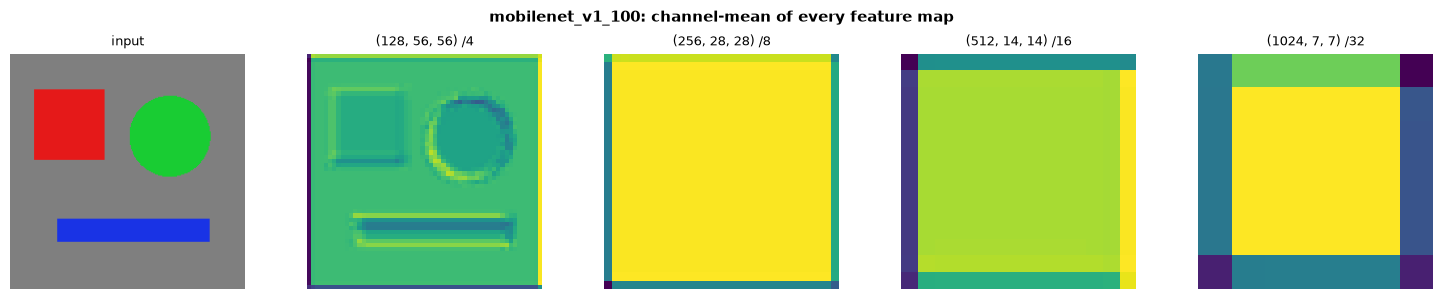

In [15]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [16]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# ── Code Walkthrough ──────────────────────────────────────────────────────────

import torch

# 1. Inspect the DWSConv building block
dws = _DWSConv(in_chs=64, out_chs=128, stride=2)
print('DWSConv(64→128, s=2):')
print(dws)

x = torch.randn(1, 64, 32, 32)
y = dws(x)
print(f'\nInput shape:  {tuple(x.shape)}')
print(f'Output shape: {tuple(y.shape)}')

# 2. Depthwise params vs. standard
std_params = 3*3*64*128
dw_params  = 3*3*64          # depthwise: one filter per input channel
pw_params  = 64*128          # pointwise: cross-channel 1x1
print(f'\nStandard 3×3 params: {std_params:,}')
print(f'DW params:           {dw_params:,}')
print(f'PW params:           {pw_params:,}')
print(f'DW+PW params:        {dw_params+pw_params:,} ({(dw_params+pw_params)/std_params:.3f}× of standard)')

DWSConv(64→128, s=2):
_DWSConv(
  (dw): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=64, bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (pw): Sequential(
    (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
)

Input shape:  (1, 64, 32, 32)
Output shape: (1, 128, 16, 16)

Standard 3×3 params: 73,728
DW params:           576
PW params:           8,192
DW+PW params:        8,768 (0.119× of standard)


In [18]:
# ── Usage Example ─────────────────────────────────────────────────────────────

# Build MobileNetV1 with full width
backbone = build_vision_backbone('mobilenet_v1_100', img_size=224)
backbone.eval()

x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print('MobileNetV1-1.0 outputs:')
print(f'  pooled_output: {tuple(out.pooled_output.shape)}')
for i, fm in enumerate(out.feature_maps):
    print(f'  feature_maps[{i}]: {tuple(fm.shape)}')

print(f'\nParameters: {backbone.num_parameters():,}')

# Compare variants
for name in ['mobilenet_v1_025', 'mobilenet_v1_050', 'mobilenet_v1_075', 'mobilenet_v1_100']:
    b = build_vision_backbone(name)
    print(f'  {name}: embed_dim={b.embed_dim}, params={b.num_parameters():,}')

MobileNetV1-1.0 outputs:
  pooled_output: (2, 1024)
  feature_maps[0]: (2, 128, 56, 56)
  feature_maps[1]: (2, 256, 28, 28)
  feature_maps[2]: (2, 512, 14, 14)
  feature_maps[3]: (2, 1024, 7, 7)

Parameters: 3,206,976
  mobilenet_v1_025: embed_dim=256, params=213,072
  mobilenet_v1_050: embed_dim=512, params=818,592
  mobilenet_v1_075: embed_dim=768, params=1,816,560


  mobilenet_v1_100: embed_dim=1024, params=3,206,976


## References

| # | Citation |
|---|----------|
| [1] | Howard, A. G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M., & Adam, H. (2017). **MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications.** arXiv:1704.04861. |
| [2] | Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). **MobileNetV2: Inverted Residuals and Linear Bottlenecks.** CVPR. arXiv:1801.04381. |
| [3] | Howard, A., Sandler, M., Chu, G., et al. (2019). **Searching for MobileNetV3.** ICCV. arXiv:1905.02244. |
| [4] | He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Deep Residual Learning for Image Recognition.** CVPR. |

---
*Notebook: MobileNetV1 — HaleBlocks backbone family*  
*Architecture: `hale_core.nn.vision.cnn.mobilenet_v1`*